In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.9  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

## Procedure

1. Set the config to a constrained linear spring:

```
component=VirtualComponent(
    spring=ConstrainedLinearSpring(10.0, n=np.array([[1], [0], [1]])),
    damper=LinearDamper(1.5),
    s_param=1.0,
    name="lin_seg3",
),
goal=go_x_y,
```

2. `bash ../start_arm.sh`
3. `cd ConstrainedSpring && python3 ../VMC/GUI_MultiVMC_Torque.py`
4. `source publish_pos.sh`

For the linear run, the same with `spring=LinearSpring(10.0)`.

# Cart (Constrained) vs Linear Spring: X-Y Plane Trajectory Comparison

End-effector trajectory in the x-y plane for:
- **Cart spring** (K=10): force only along its direction n, so in x-y the tip moves along the x-axis, with no y movement
- **Linear spring** (K=10): free motion in both x and y

Reference: stepped along the 45° diagonal to (20, 20), (40, 40) and (60, 60) cm (`publish_pos.sh`).
The markers ("Attachment 1-3") show the tip 1 s after each step.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection

# Load data
constrained_data = np.load('outputs/constrained_spring/constrained_k10.npz')
linear_data = np.load('outputs/constrained_spring/linear_k10.npz')

print(f"Constrained: {len(constrained_data['t'])} samples")
print(f"Linear: {len(linear_data['t'])} samples")

# Extract common variables
datasets = {
    'Cart (K=10)': constrained_data,
    'Linear (K=10)': linear_data
}

# Find t=0 (when reference starts moving in x)
# and t=end (when reference returns to x=0)
trajectories = {}

for name, data in datasets.items():
    t = data['t']
    goal = data['goal']  # (n, N_VC, 3)
    comp_pos = data['comp_pos']  # (n, N_VC, 3)
    
    # Get reference x position
    ref_x = goal[:, 0, 0]  # First VC, x coordinate
    
    # Find when reference starts moving (ref_x != 0)
    nonzero_idx = np.where(np.abs(ref_x) > 1e-6)[0]
    t_start_idx = nonzero_idx[0] if len(nonzero_idx) > 0 else 0
    
    # Find when reference returns to near 0 (after reaching max)
    max_x_idx = np.argmax(np.abs(ref_x))
    returning = np.where(np.abs(ref_x[max_x_idx:]) < 1e-6)[0]
    t_end_idx = max_x_idx + returning[0] if len(returning) > 0 else len(ref_x) - 1
    
    # Extract trajectory window
    t_window = t[t_start_idx:t_end_idx]
    t_relative = t_window - t_window[0]  # Normalize to start at 0
    
    ee_pos = comp_pos[t_start_idx:t_end_idx, 0, :2] * 100.0  # x, y positions [m -> cm]
    ref_pos = goal[t_start_idx:t_end_idx, 0, :2] * 100.0     # reference x, y [m -> cm]
    
    trajectories[name] = {
        't': t_relative,
        'ee_xy': ee_pos,
        'ref_xy': ref_pos,
        'duration': t_relative[-1]
    }
    
    print(f"\n{name}:")
    print(f"  Duration: {trajectories[name]['duration']:.2f} s")
    print(f"  EE x range: [{ee_pos[:, 0].min():.4f}, {ee_pos[:, 0].max():.4f}] cm")
    print(f"  EE y range: [{ee_pos[:, 1].min():.4f}, {ee_pos[:, 1].max():.4f}] cm")

Constrained: 3616 samples
Linear: 3237 samples

Cart (K=10):
  Duration: 10.96 s
  EE x range: [-0.0013, 27.0816] cm
  EE y range: [-0.3717, 0.0028] cm

Linear (K=10):
  Duration: 9.80 s
  EE x range: [-0.0000, 22.7523] cm
  EE y range: [-0.0007, 21.0069] cm


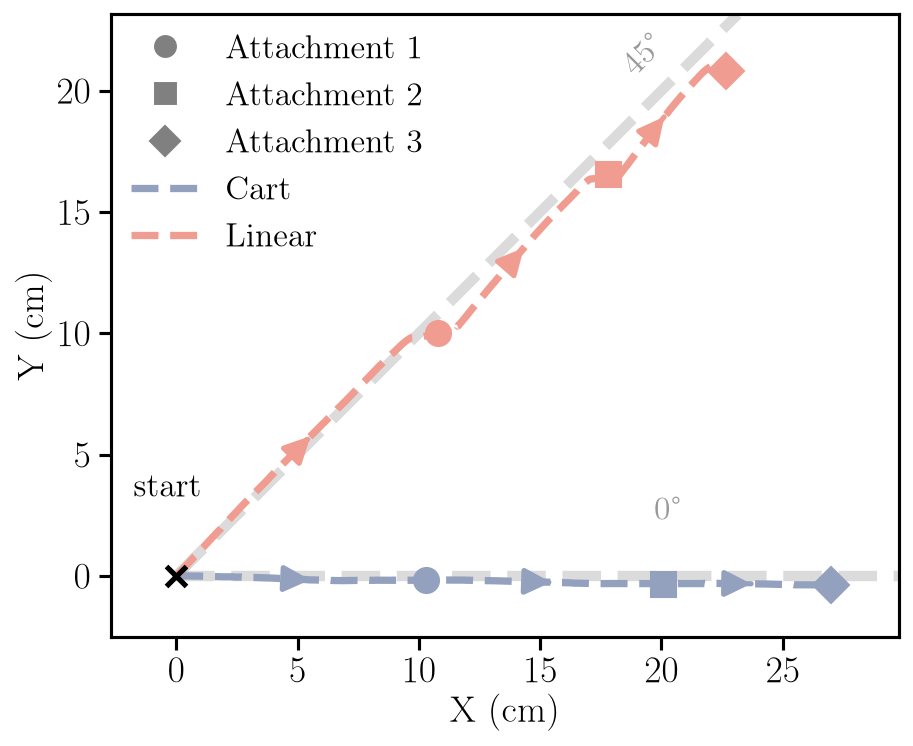


✓ Trajectory comparison complete
  Pastel navy = Cart spring (confined to x-axis)
  Pastel coral = Linear spring (free 2D motion)
  Dashed gray bands = 0° (cart's driven axis) and 45° (attachment direction)
  Arrowheads on each trajectory show the direction of motion
  Markers placed 1 s after each reference attachment change:
    ○ = Attachment 1  □ = Attachment 2  ◇ = Attachment 3


In [3]:
# Reference step positions (from bash script) [cm]
ref_steps = np.array([
    [20.0, 20.0],  # Step 1: x=20, y=20 cm
    [40.0, 40.0],  # Step 2: x=40, y=40 cm
    [60.0, 60.0],  # Step 3: x=60, y=60 cm
])

# Markers for all three attachments
step_markers = ['o', 's', 'D']  # circle for attachment 1, square for 2, diamond for 3
marker_size = 12
time_shift = 1.0  # [s] Shift markers by 1 second after reference attachment change

def find_step_indices_with_shift(t, ref_xy, time_shift):
    """Find indices where reference reaches each attachment, plus time_shift offset."""
    step_indices = []
    for step in ref_steps:
        distances = np.linalg.norm(ref_xy - step, axis=1)
        step_time_idx = np.argmin(distances)
        step_time = t[step_time_idx]
        
        # Find index at time + shift
        target_time = step_time + time_shift
        time_diffs = np.abs(t - target_time)
        shifted_idx = np.argmin(time_diffs)
        
        step_indices.append(shifted_idx)
    return step_indices

def add_motion_arrows(ax, xy, boundaries, color, mid_frac=0.5, tip_frac=0.045, zorder=4, size=26):
    """One arrowhead per phase (start -> attachment 1 -> 2 -> 3), placed at
    the arc-length midpoint of that phase.

    Placing arrows by sample-index fraction of the whole trajectory doesn't
    work here: the tip reaches its (spring-compliant) equilibrium early in
    each phase and then just sits there, so most samples -- especially in
    the long final phase -- carry almost no motion. Anchoring to each
    phase's own arc length instead guarantees every arrow sits where the tip
    is actually moving, and keeps arrows off the attachment markers, which
    sit at the phase boundaries.
    """
    for b0, b1 in zip(boundaries[:-1], boundaries[1:]):
        if b1 <= b0 + 1:
            continue
        seg = xy[b0:b1 + 1]
        arc = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(seg, axis=0), axis=1))])
        if arc[-1] == 0:
            continue
        i0 = np.searchsorted(arc, arc[-1] * mid_frac)
        i1 = np.searchsorted(arc, arc[-1] * min(1.0, mid_frac + tip_frac))
        i0, i1 = min(i0, len(seg) - 1), min(max(i1, i0 + 1), len(seg) - 1)
        p0, p1 = seg[i0], seg[i1]
        if np.allclose(p0, p1):
            continue
        ax.annotate('', xy=p1, xytext=p0,
                    arrowprops=dict(arrowstyle='-|>', color=color, lw=2.5, mutation_scale=size),
                    zorder=zorder)

# Auto-scale bounds (10% padding, anchored to include the origin) -- computed
# up front so the direction guide lines/labels below can be sized to land
# inside the visible frame instead of past its edge.
all_ee_points = np.vstack([traj['ee_xy'] for traj in trajectories.values()])
x_margin = (all_ee_points[:, 0].max() - all_ee_points[:, 0].min()) * 0.1
y_margin = (all_ee_points[:, 1].max() - all_ee_points[:, 1].min()) * 0.1
xlim = (min(0, all_ee_points[:, 0].min()) - x_margin, all_ee_points[:, 0].max() + x_margin)
ylim = (min(0, all_ee_points[:, 1].min()) - y_margin, all_ee_points[:, 1].max() + y_margin)

# Plot: X-Y plane comparison on SAME graph
fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.75))

# Color and style for each configuration (pastel navy/coral)
config_styles = {
    'Cart (K=10)': {'color': '#94A1BE', 'ee_lw': 3.5},
    'Linear (K=10)': {'color': '#F19C90', 'ee_lw': 3.5}
}

# Guide lines showing the two directions at play: 0 deg is the axis the cart
# spring is actually driven along; 45 deg is the direction of the commanded
# attachments (all three sit on y=x). Thick + transparent + low zorder, so
# they read as a soft band sitting *under* the pastel trajectories rather
# than competing with them. Angle labels are sized to match the legend text.
guide_color = '#999999'
guide_lw = 5.0
guide_alpha = 0.35
guide_len = min(xlim[1], ylim[1])
ax.plot([0, xlim[1]], [0, 0], linestyle='--', color=guide_color, linewidth=guide_lw, alpha=guide_alpha, zorder=1)
ax.plot([0, guide_len], [0, guide_len], linestyle='--', color=guide_color, linewidth=guide_lw, alpha=guide_alpha, zorder=1)
# "0 deg" label: upper-left of the line's right end, clear of the cart trajectory
ax.text(xlim[1] * 0.68, (ylim[1] - ylim[0]) * 0.08, '0°', color=guide_color, fontsize=LEGEND_FONT_SIZE,
        ha='center', va='bottom', zorder=1)
ax.text(guide_len * 0.88, guide_len * 0.88, '45°', color=guide_color, fontsize=LEGEND_FONT_SIZE,
        ha='right', va='bottom', zorder=1, rotation=45)

# Plot both trajectories
for config_idx, (name, traj) in enumerate(trajectories.items()):
    t = traj['t']
    ee_xy = traj['ee_xy']
    color = config_styles[name]['color']
    
    # Dashed line: end-effector trajectory. Legend label drops "(K=10)" -- both
    # configs share the same k, so it's redundant here (still printed above).
    short_name = name.split(' (')[0]
    ax.plot(ee_xy[:, 0], ee_xy[:, 1], 
            color=color, linewidth=config_styles[name]['ee_lw'], linestyle='--',
            label=short_name, zorder=3)
    
    # Find attachment positions on end-effector trajectory (with time_shift)
    step_indices = find_step_indices_with_shift(t, traj['ref_xy'], time_shift)
    
    # One arrow per phase (start->A1, A1->A2, A2->A3) showing direction of motion
    add_motion_arrows(ax, ee_xy, [0] + step_indices, color)
    
    for step_num, idx in enumerate(step_indices):
        marker = step_markers[step_num]
        
        if idx < len(ee_xy):
            ax.plot(ee_xy[idx, 0], ee_xy[idx, 1], 
                    marker=marker, color=color, markersize=marker_size, 
                    markerfacecolor=color, zorder=5)

# Mark and label the common starting point -- both trajectories begin here,
# before the reference issues its first attachment. Label sits above and to
# the left, clear of both trajectories (Cart heads +x, Linear heads +x/+y).
ax.plot(0, 0, marker='x', color='black', markersize=10, markeredgewidth=2.5, zorder=6)
ax.annotate('start', xy=(0, 0), xytext=(12, 35), textcoords='offset points',
            fontsize=LEGEND_FONT_SIZE, ha='right', va='bottom', zorder=6)

# Legend for attachment markers -- numbered only, no coordinates: the
# marker's position along each trajectory is a time-shifted snapshot after
# each attachment change, not the literal attachment coordinate, so printing
# "(x, y) cm" here would overstate precision.
from matplotlib.lines import Line2D
step_legend = [Line2D([0], [0], marker=step_markers[i], color='w', 
                      markerfacecolor='gray', markersize=12, label=f'Attachment {i + 1}')
               for i in range(len(ref_steps))]

# Combine legends -- attachments first, then Cart, then Linear
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=step_legend + handles, loc='upper left', 
         framealpha=0.95, ncol=1)

# Labels and formatting
ax.set_xlabel('X (cm)')
ax.set_ylabel('Y (cm)')
ax.grid(GRID)
ax.set_aspect('equal')
ax.set_xlim(*xlim)
ax.set_ylim(*ylim)

plt.tight_layout()
plt.savefig(os.path.join('outputs', 'constrained_spring', 'xy_trajectory_markers.pdf'))
plt.show()

print("\n✓ Trajectory comparison complete")
print("  Pastel navy = Cart spring (confined to x-axis)")
print("  Pastel coral = Linear spring (free 2D motion)")
print("  Dashed gray bands = 0° (cart's driven axis) and 45° (attachment direction)")
print("  Arrowheads on each trajectory show the direction of motion")
print(f"  Markers placed {time_shift:.0f} s after each reference attachment change:")
print("    ○ = Attachment 1  □ = Attachment 2  ◇ = Attachment 3")

In [4]:
# Summary: Y-axis motion comparison
print("\n=== Y-AXIS MOTION COMPARISON ===")
print(f"{'Type':<20} | {'Y Min [cm]':>12} | {'Y Max [cm]':>12} | {'Y Range [cm]':>12}")
print("-" * 60)

for name, traj in trajectories.items():
    ee_xy = traj['ee_xy']
    y_min = ee_xy[:, 1].min()
    y_max = ee_xy[:, 1].max()
    y_range = y_max - y_min
    print(f"{name:<20} | {y_min:>12.4f} | {y_max:>12.4f} | {y_range:>12.4f}")

print("\n→ Cart spring: Y range ≈ 0 (confined to x-axis)")
print("→ Linear spring: Y range > 0 (free motion in both axes)")


=== Y-AXIS MOTION COMPARISON ===
Type                 |   Y Min [cm] |   Y Max [cm] | Y Range [cm]
------------------------------------------------------------
Cart (K=10)          |      -0.3717 |       0.0028 |       0.3746
Linear (K=10)        |      -0.0007 |      21.0069 |      21.0076

→ Cart spring: Y range ≈ 0 (confined to x-axis)
→ Linear spring: Y range > 0 (free motion in both axes)
